# mHealth HAR — reproducible evidence walkthrough

## tl;dr

The original 12-class CNN + BiLSTM records **92.91% test accuracy** and **92.80% Macro-F1** on **987 windows**. This notebook audits existing aggregate evidence and plots saved experimental history. It does **not** train a model. Saved-checkpoint inference was verified separately; full retraining is unverified.

Read `../docs/SCIENTIFIC_AUDIT.md` for historical 11/12-class inconsistencies, unequal baseline settings, and subject-independence limits.

## Context & Methods

This is a compact guide to the reusable package and original evidence, replacing repeated exploratory cells while preserving the original notebook separately.

### Key Assumptions

- Contiguous equal-label runs are CSV row-order proxies, not verified subjects or sessions.
- Complete runs are assigned before 128 × 23 windows with stride 64 are formed.
- Standardization is fitted on training rows only.
- The recorded CNN uses its final executed epoch; hybrid and recurrent models select validation Macro-F1.
- Original evidence is kept immutable. Recomputed metrics and plots are labeled as audits or redraws, not new experiments.

### 1. Locate the repository and import reusable modules

Install the package first with `python -m pip install -e '.[dev]'`. Execution works from the root or this notebook directory.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display
from mhealth_har.config import load_config
from mhealth_har.evaluation import audit_saved_results
from mhealth_har.figures import make_figures

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
assert (ROOT / "pyproject.toml").exists(), "Run from the project root or notebooks directory."
EVIDENCE = ROOT / "evidence" / "original"

## Data

The supplied derivative contains 308,021 rows, 23 numeric channels, 12 target labels, and no subject/session IDs. Raw data are not required for this evidence walkthrough.

### 2. Inspect recorded partition sizes

In [2]:
summary = pd.read_csv(EVIDENCE / "dataset_summary.csv")
display(summary)
assert summary["Windows"].tolist() == [3127, 582, 987]

,Dataset,Raw_Samples,Windows,Window_Size,Overlap,Features_Per_Window,Activity_Runs
0,Train,205108,3127,128,64,23,70
1,Validation,38092,582,128,64,23,12
2,Test,64821,987,128,64,23,23


Target ratios 70/15/15 apply to per-activity run allocation. Rounding with few runs produces different window proportions; only 12 label runs form the validation partition.

### 3. Inspect the exact portable hybrid configuration

In [3]:
config = load_config(ROOT / "configs" / "hybrid.json")
display(pd.Series(config, name="Hybrid setting").to_frame())

,Hybrid setting
data_dir,data/processed
seed,43
batch_size,32
epochs,35
learning_rate,0.00025
weight_decay,0.0001
l2,0.00015
input_noise,0.015
input_dropout,0.1
cnn_dropout,0.2


## Results

### 4. Reconcile recorded metrics against original confusion counts

The audit reconstructs class-index counts from each confusion matrix and recomputes all metrics using the same metric function as evaluation. It does not synthesize sensor records or produce model predictions.

In [4]:
audited = audit_saved_results(EVIDENCE)
names = {
    "cnn_multiscale_bilstm_11class": "Multi-scale CNN + BiLSTM",
    "cnn_only_12class": "Multi-scale CNN",
    "lstm_only_generalization_v1": "Stacked LSTM",
    "bilstm_only_generalization_v1": "Stacked BiLSTM",
}
primary = audited[audited.Classes == 12].copy()
primary["Experiment"] = primary["Experiment"].map(names)
display(primary.round(6))
display(audited[audited.Classes == 11].round(6))

,Experiment,Classes,Test_windows,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1
0,Stacked BiLSTM,12,987,0.872340,0.898333,0.879429,0.868483,0.866592
1,Multi-scale CNN + BiLSTM,12,987,0.929078,0.943413,0.933336,0.928040,0.926785
3,Multi-scale CNN,12,987,0.898683,0.937390,0.903618,0.900156,0.893347
4,Stacked LSTM,12,987,0.858156,0.890215,0.860197,0.852980,0.855278


,Experiment,Classes,Test_windows,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1
2,cnn_only_11class,11,893,0.930571,0.947703,0.938689,0.930319,0.927416


The hybrid has the highest recorded test accuracy among the four 12-class experiments. Unequal weights, budgets, and checkpoint rules prevent a controlled architectural attribution. The separate 11-class CNN excludes sitting and is evaluated on 893 windows.

### 5. Plot the original hybrid confusion counts

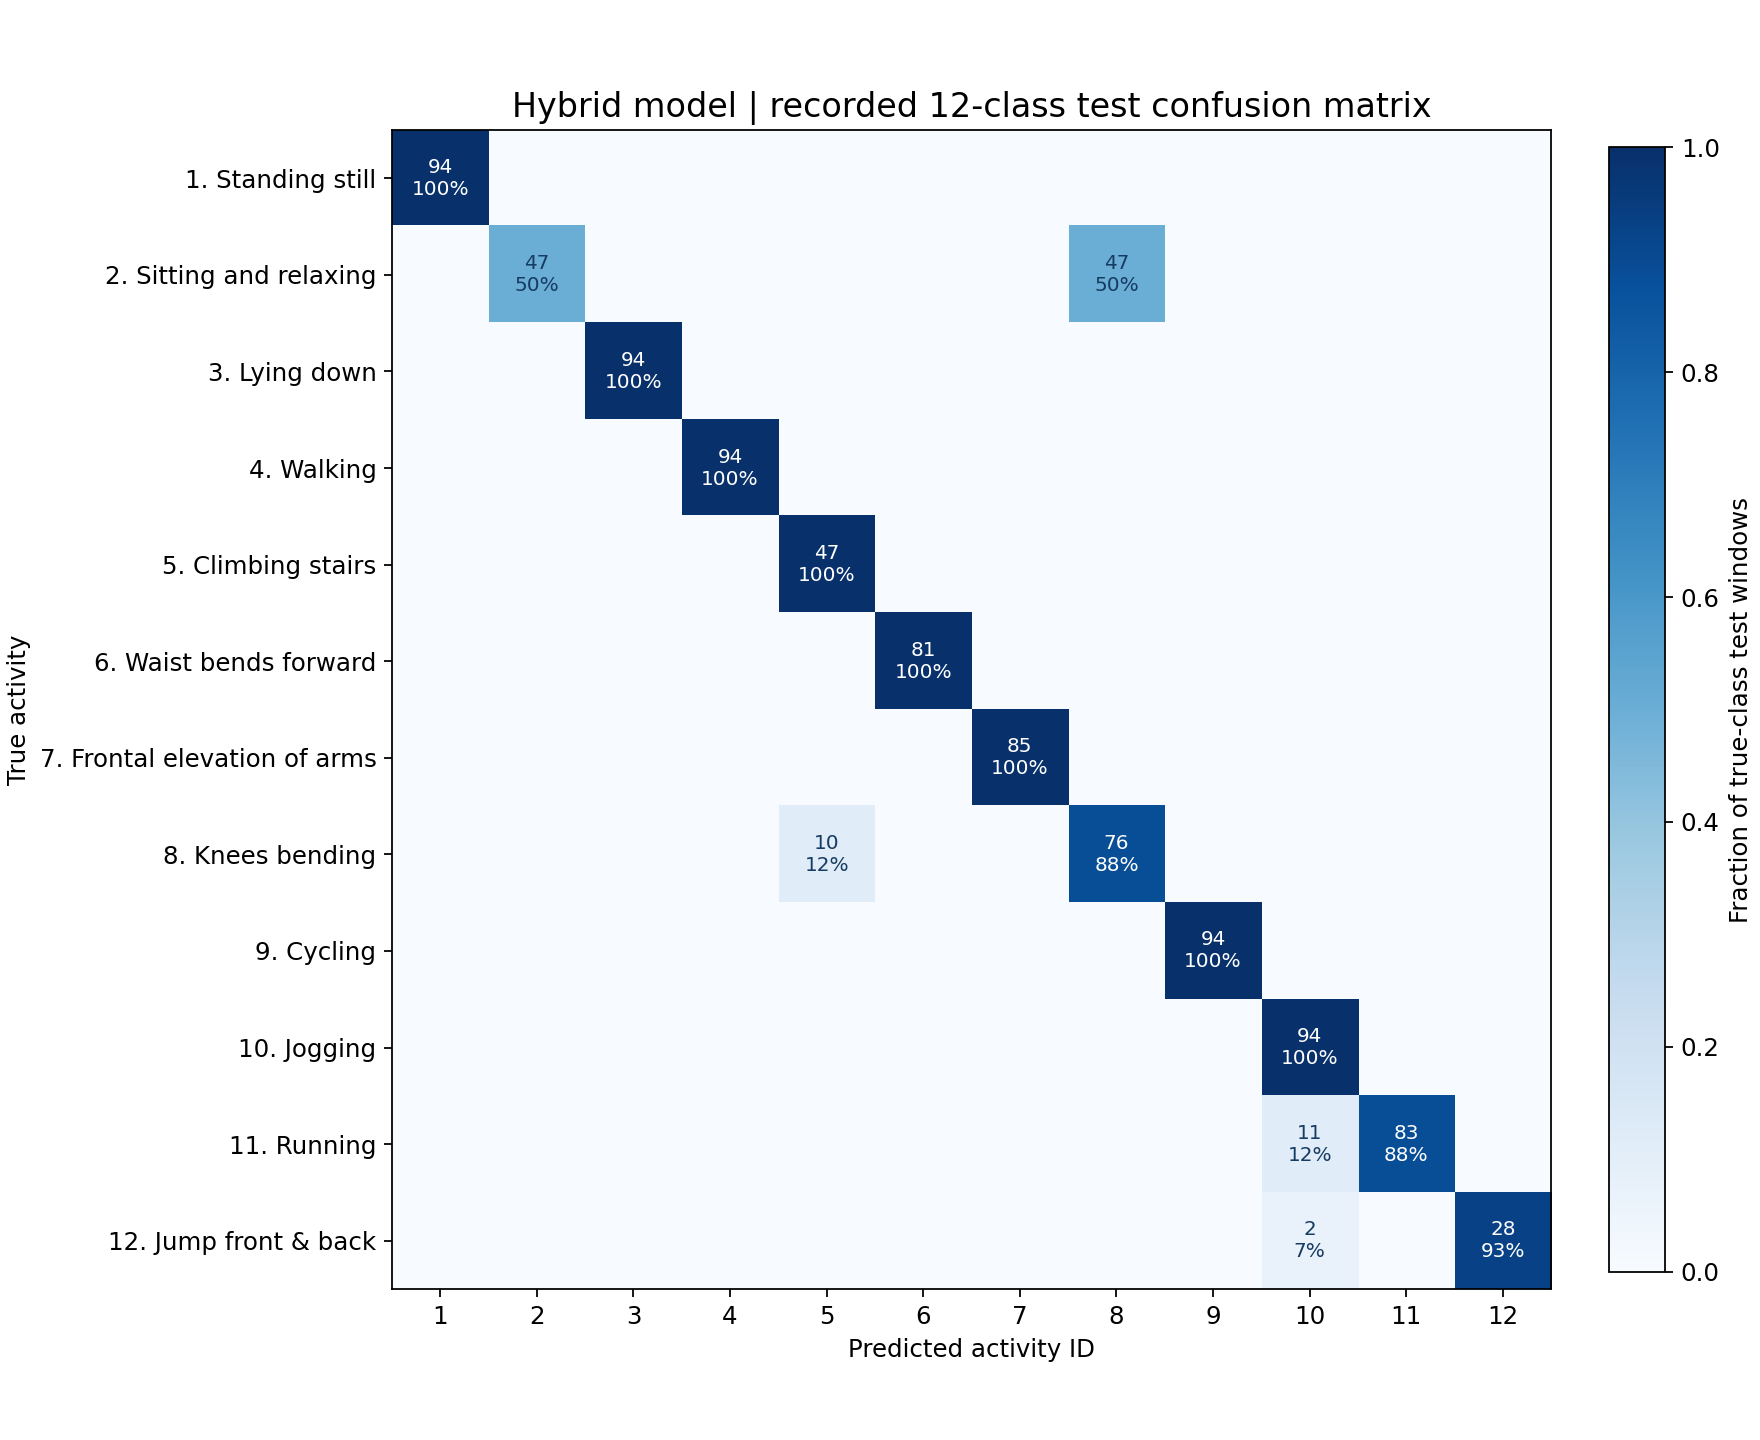

In [5]:
figure_paths = make_figures(EVIDENCE, ROOT / "assets" / "figures")
display(Image(filename=str(figure_paths[0]), width=900))

Half of the sitting test windows are classified as knees bending (47 of 94). This is the largest observed confusion; its physical cause is not established by these results.

### 6. Inspect the complete error counts

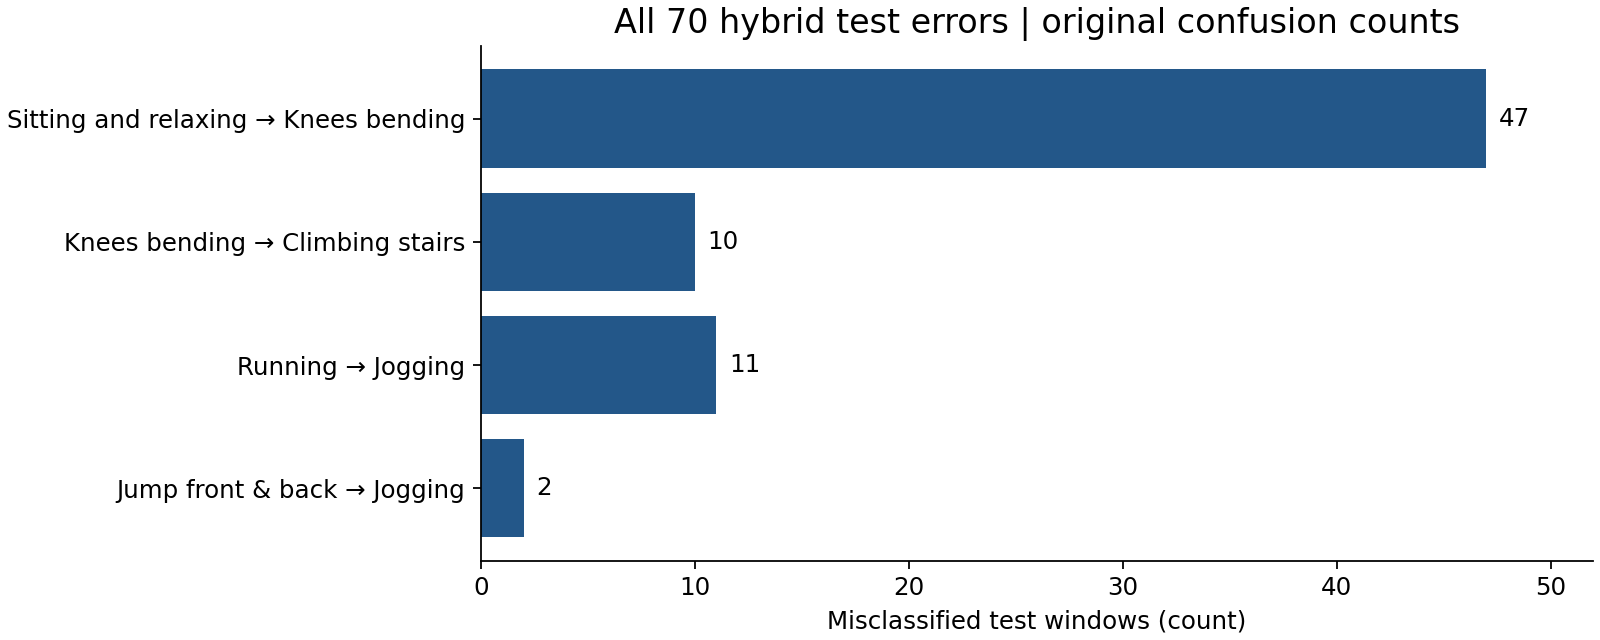

In [6]:
display(Image(filename=str(figure_paths[2]), width=900))

All 70 errors are accounted for by the four nonzero off-diagonal confusion entries. Original raw and normalized matrices remain in `evidence/original/`.

### 7. Inspect saved training history

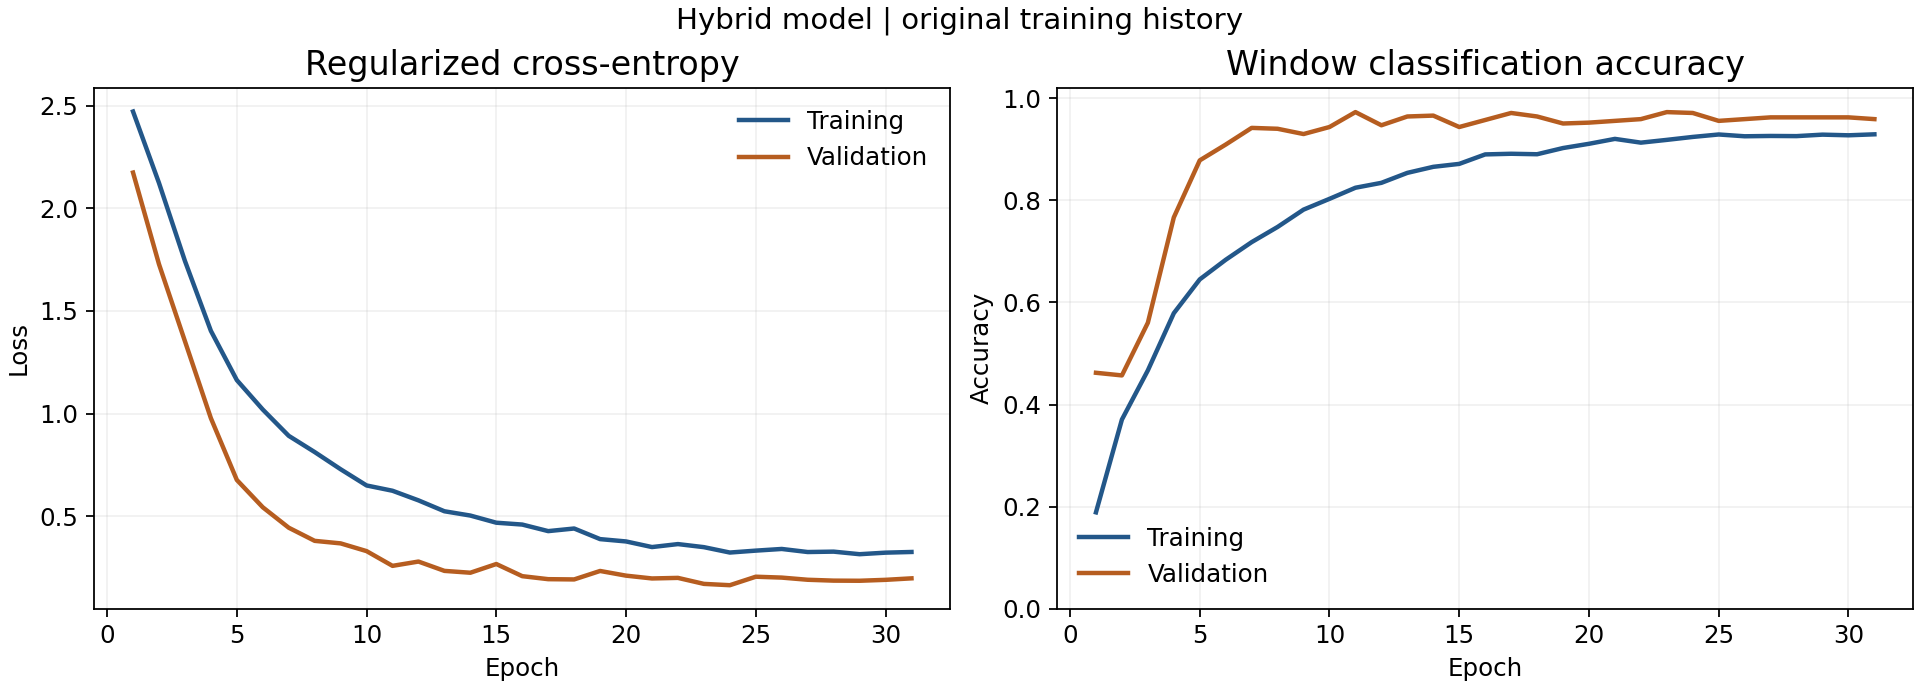

In [7]:
display(Image(filename=str(figure_paths[1]), width=1000))

These curves come from the original history CSV. They describe the training run, while the hybrid's reported evaluation uses the validation-Macro-F1-selected checkpoint rather than necessarily the final epoch.

### 8. Inspect checks actually performed during conversion

In [8]:
for filename in ("preprocessing_validation.json", "checkpoint_validation.json"):
    status = json.loads((ROOT / "evidence" / filename).read_text())
    print(filename)
    print(json.dumps(status, indent=2))

preprocessing_validation.json
{
  "run_assignments_exactly_equal": true,
  "splits": [
    {
      "split": "train",
      "X_shape": [
        3127,
        128,
        23
      ],
      "X_exactly_equal": false,
      "X_max_absolute_difference": 1.9073486328125e-06,
      "X_within_absolute_tolerance": 3e-06,
      "y_exactly_equal": true
    },
    {
      "split": "validation",
      "X_shape": [
        582,
        128,
        23
      ],
      "X_exactly_equal": false,
      "X_max_absolute_difference": 9.5367431640625e-07,
      "X_within_absolute_tolerance": 3e-06,
      "y_exactly_equal": true
    },
    {
      "split": "test",
      "X_shape": [
        987,
        128,
        23
      ],
      "X_exactly_equal": false,
      "X_max_absolute_difference": 1.9073486328125e-06,
      "X_within_absolute_tolerance": 3e-06,
      "y_exactly_equal": true
    }
  ]
}
checkpoint_validation.json
{
  "tensorflow": "2.20.0",
  "keras": "3.13.2",
  "status": "saved-checkpoint infer

## Takeaways

- The primary historical result is traceable to metrics, confusion counts, and validated saved-checkpoint inference.
- The refactor retains methodology and avoids blending 11-class results into the 12-class comparison.
- Preprocessing run assignments and labels match exactly; standardized arrays agree within 3e-6 absolute tolerance.
- Missing subject/session IDs, overlapping windows, oracle activity segmentation, and unequal baseline settings limit conclusions.

To rebuild and train, follow `../README.md` from the project root. Training is deliberately a separate CLI command, so opening this notebook never starts expensive experiments. Full initialization-to-results retraining, unseen-subject validation, and GitHub-hosted CI remain unverified.